# 01 · Training

How the station-correction models train: the data split, the loss curves of the six website
models, the effect of the learning rate on the curves, the differences between the held-out
station groups, and whether the checkpoint chosen on the validation period is also good on the
test period. The scores of all configurations are in `02_experiments.ipynb`.

**What is trained.** A network predicts the correction $\mathbf y = \mathbf u_\text{obs} - \bar{\mathbf u}$
of the 10 m wind vector at a station, where $\bar{\mathbf u}$ is the mean of the input forecasts
(IFS + AIFS, or IFS + GFS + MEPS + AROME-Arctic) at the station, for forecast leads 0–66 h every 6 h.
Inputs: the input forecasts on the 0.25° grid (read by a neural operator, if the model has one) and
the 1 km terrain descriptors of the point. No station identity enters, so the trained model can be
applied at every 1 km cell.

**Loss.** The mean squared vector error, scaled by the spread of the target:
$$\mathcal L = \frac{1}{n}\sum \frac{\lVert \hat{\mathbf y} - \mathbf y\rVert^2}{\sigma_y^2},$$
with $\sigma_y$ the standard deviation of $\mathbf y$ over the training runs. In this notebook the
loss is converted back to the vector RMSE of the corrected wind in m/s, $\sigma_y\sqrt{\mathcal L}$,
and to its change in % against no correction ($\hat{\mathbf y} = 0$, i.e. the input mean itself) on
the same stations and runs. Negative = the model improves on its input.

**Training.** AdamW (weight decay $10^{-4}$), one-cycle learning-rate schedule, batch 16, 40
epochs. After every epoch the validation loss is computed; the weights of the epoch with the lowest
validation loss are kept (`best.pt`) and used for all predictions.

In [1]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import runlib as R

plt.rcParams.update({'figure.dpi': 110, 'axes.grid': True, 'grid.alpha': .3, 'axes.spines.top': False,
                     'axes.spines.right': False, 'legend.frameon': False})
sc = R.Scorer()
SAMPLE = {'ecmwf': sc.ecmwf, 'nwp': sc.nwp}
G = sc.groups
print(f'{len(G)} stations in {G.max() + 1} groups; target scale sigma_y = {sc.ecmwf.y_std:.2f} m/s (IFS + AIFS), '
      f'{sc.nwp.y_std:.2f} m/s (four models)')

99 stations in 5 groups; target scale sigma_y = 2.80 m/s (IFS + AIFS), 2.60 m/s (four models)


## 1 · Data split

* **Time.** Training runs 2024-03-01 – 2024-12-31, validation 2025-01-01 – 2025-03-31, test
  2025-04-01 – 2025-09-12 (00 and 12 UTC runs). The validation period is winter, the test period
  spring and summer, so the two have different error levels.
* **Space.** The 99 stations are split into 5 spatially blocked groups (k-means on the station
  positions). A run of *fold k* trains on the other four groups and is validated and tested on
  group k only, so every score is on stations the model never saw. Each fold is trained with 3
  random seeds: 15 runs per configuration.

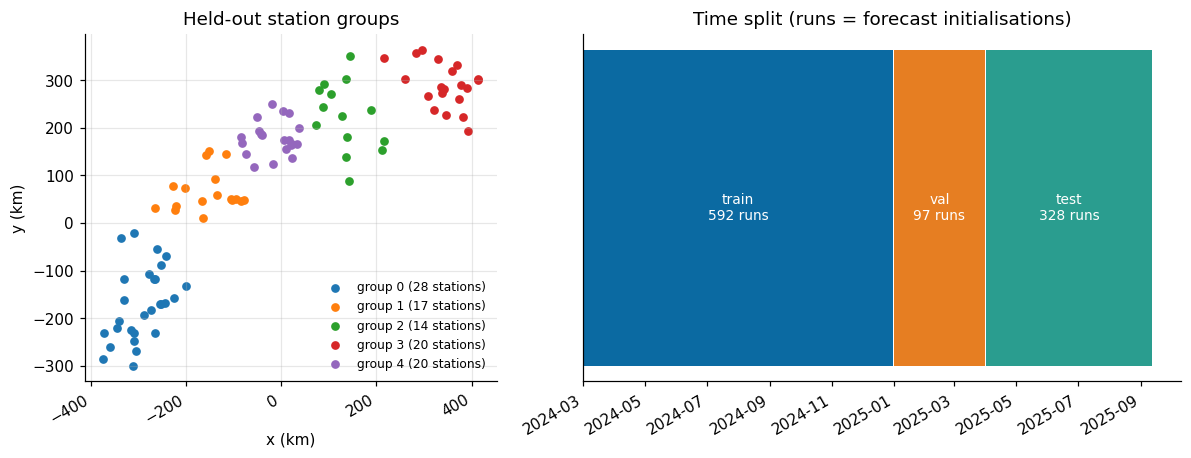

In [2]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4.2), gridspec_kw={'width_ratios': [1, 1.4]})
xy = sc.ecmwf.xy
for k in range(5):
    ax[0].scatter(xy[G == k, 0], xy[G == k, 1], s=22, label=f'group {k} ({(G == k).sum()} stations)')
ax[0].set(aspect='equal', xlabel='x (km)', ylabel='y (km)', title='Held-out station groups')
ax[0].legend(fontsize=8, loc='lower right')
inits = sc.ecmwf.inits
for i, (name, col) in enumerate(zip(R.SPLIT, ['#0b6aa2', '#e67e22', '#2a9d8f'])):
    m = sc.ecmwf.period(name) & (sc.nwp.keep if name == 'test' else True)
    a, b = pd.Timestamp(R.SPLIT[name][0]), pd.Timestamp(R.SPLIT[name][1])
    ax[1].barh(0, (b - a).days, left=a, height=.5, color=col)
    ax[1].text(a + (b - a) / 2, 0, f'{name}\n{m.sum()} runs', ha='center', va='center', color='white', fontsize=9)
ax[1].set(yticks=[], title='Time split (runs = forecast initialisations)')
ax[1].grid(False)
fig.autofmt_xdate()
plt.tight_layout()

## 2 · Loss curves of the six website models

All at learning rate $10^{-5}$. First the loss $\mathcal L$ exactly as it is logged during
training. Thin lines are the 15 runs, the thick line is their mean; the dotted line is the loss of
no correction ($\hat{\mathbf y} = 0$, i.e. $\overline{\lVert\mathbf y\rVert^2}/\sigma_y^2$). The
**training** curve is on the four training groups, the **validation** curve on the held-out group,
both in the respective period, so their levels are not comparable with each other; what matters is
how far each lies below its no-correction line.

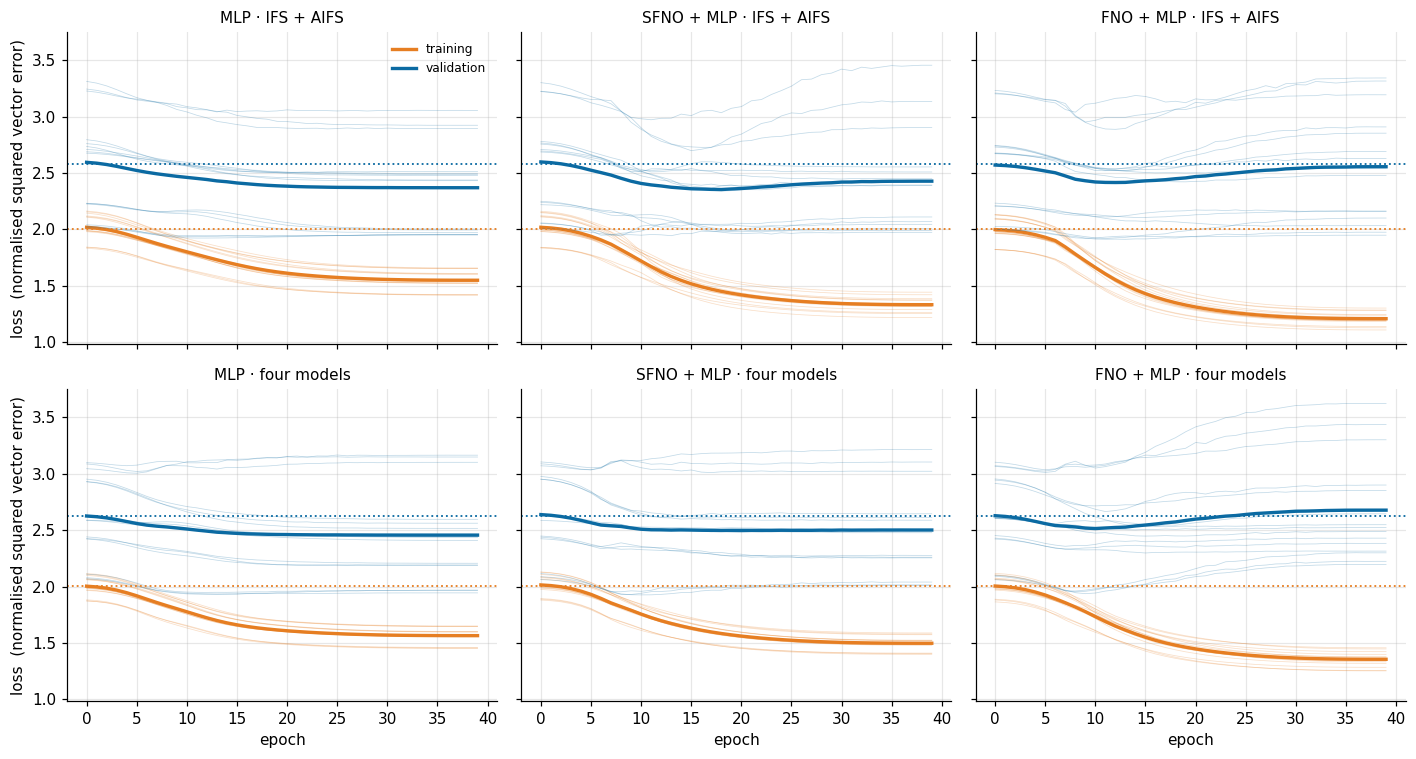

In [3]:
def no_corr(sample, period, mask):
    # vector RMSE of the input mean itself (no correction) on stations `mask` in `period`
    y = (sample.obs - sample.base)[sample.period(period)][:, :, mask]
    return float(np.sqrt(np.nanmean((y ** 2).sum(-1))))

NC = {(g, k): (no_corr(SAMPLE[g], 'train', G != k), no_corr(SAMPLE[g], 'val', G == k))
      for g in SAMPLE for k in range(5)}

def curves(pattern, group='ecmwf'):
    # one row per run: train / validation RMSE (m/s) and change against no correction (%) per epoch
    h = R.histories(pattern)
    s = SAMPLE[group].y_std
    nc = np.array([NC[(group, k)] for k in h.fold])                       # (runs, 2)
    h['train_rmse'] = [s * np.sqrt(t) for t in h.train]
    h['val_rmse'] = [s * np.sqrt(v) for v in h.val]
    h['train_pct'] = [(r / c - 1) * 100 for r, c in zip(h.train_rmse, nc[:, 0])]
    h['val_pct'] = [(r / c - 1) * 100 for r, c in zip(h.val_rmse, nc[:, 1])]
    h['nc_train'], h['nc_val'] = nc[:, 0], nc[:, 1]
    h['best_epoch'] = [int(np.argmin(v)) for v in h.val]
    return h

WEB = [('MLP · IFS + AIFS', 'point_terrain_g{k}_s{s}_lr1e-05', 'ecmwf'),
       ('SFNO + MLP · IFS + AIFS', 'sfno_terrain_g{k}_s{s}_lr1e-05', 'ecmwf'),
       ('FNO + MLP · IFS + AIFS', 'fno_terrain_g{k}_s{s}_lr1e-05', 'ecmwf'),
       ('MLP · four models', 'point_terrain_g{k}_s{s}_nwp_lr1e-05', 'nwp'),
       ('SFNO + MLP · four models', 'sfno_terrain_g{k}_s{s}_nwp_lr1e-05', 'nwp'),
       ('FNO + MLP · four models', 'fno_terrain_g{k}_s{s}_nwp_lr1e-05', 'nwp')]
H = {lab: curves(p, g) for lab, p, g in WEB}

def loss_panels(axs, H, ylabel):
    for ax, (lab, h) in zip(axs.flat, H.items()):
        ep = np.arange(len(h.train[0]))
        for key, col, name in (('train', '#e67e22', 'training'), ('val', '#0b6aa2', 'validation')):
            a = np.stack(h[key])
            ax.plot(ep, a.T, color=col, lw=.5, alpha=.25)
            ax.plot(ep, a.mean(0), color=col, lw=2.2, label=name)
        s = SAMPLE['nwp' if 'four models' in lab else 'ecmwf'].y_std
        ax.axhline(np.mean((h.nc_train / s) ** 2), color='#e67e22', ls=':', lw=1.2)
        ax.axhline(np.mean((h.nc_val / s) ** 2), color='#0b6aa2', ls=':', lw=1.2)
        ax.set_title(lab, fontsize=10)
    for ax in axs[:, 0]: ax.set_ylabel(ylabel)
    for ax in axs[-1]: ax.set_xlabel('epoch')
    axs[0, 0].legend(loc='upper right', fontsize=8)

fig, axs = plt.subplots(2, 3, figsize=(13, 7), sharex=True, sharey=True)
loss_panels(axs, H, 'loss  (normalised squared vector error)')
plt.tight_layout()

The same curves converted to the vector RMSE of the corrected wind, $\sigma_y\sqrt{\mathcal L}$ in m/s
($\sigma_y$ = 2.80 m/s for IFS + AIFS, 2.60 m/s for the four models). The conversion is monotonic,
so the shape of every curve and the epoch of its minimum are the same as above; the RMSE has a unit,
and the two input groups (different $\sigma_y$) can be compared.

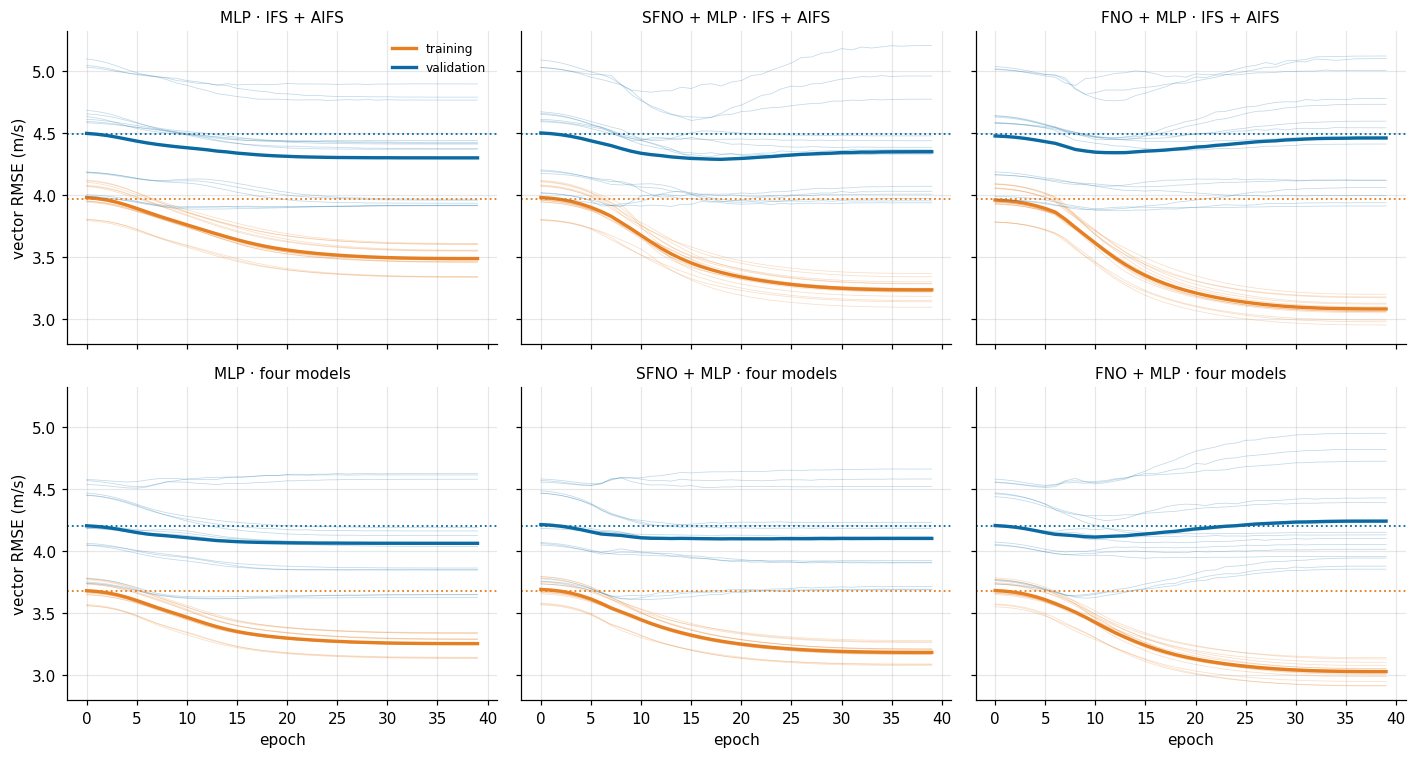

In [4]:
fig, axs = plt.subplots(2, 3, figsize=(13, 7), sharex=True, sharey=True)
for ax, (lab, h) in zip(axs.flat, H.items()):
    ep = np.arange(len(h.train_rmse[0]))
    for key, col, name in (('train_rmse', '#e67e22', 'training'), ('val_rmse', '#0b6aa2', 'validation')):
        a = np.stack(h[key])
        ax.plot(ep, a.T, color=col, lw=.5, alpha=.25)
        ax.plot(ep, a.mean(0), color=col, lw=2.2, label=name)
    ax.axhline(h.nc_train.mean(), color='#e67e22', ls=':', lw=1.2)
    ax.axhline(h.nc_val.mean(), color='#0b6aa2', ls=':', lw=1.2)
    ax.set_title(lab, fontsize=10)
for ax in axs[:, 0]: ax.set_ylabel('vector RMSE (m/s)')
for ax in axs[1]: ax.set_xlabel('epoch')
axs[0, 0].legend(loc='upper right', fontsize=8)
plt.tight_layout()

The same validation curves as a change against no correction, one line per model (mean of the 15
runs). The markers are the median epoch of the kept checkpoint.

,parameters,s / epoch,kept epoch (median),kept epoch (range),val change at kept epoch (%),val change at epoch 40 (%),train change at epoch 40 (%)
MLP · IFS + AIFS,22018,1.695362,33,10–39,-4.280745,-4.14978,-12.114262
SFNO + MLP · IFS + AIFS,606434,9.403255,17,6–37,-5.136782,-3.048205,-18.465888
FNO + MLP · IFS + AIFS,4538594,6.72054,12,8–27,-3.645409,-0.683048,-22.356128
MLP · four models,22530,1.75148,35,4–39,-3.903403,-3.449033,-11.604558
SFNO + MLP · four models,607458,8.571268,19,5–38,-3.249289,-2.478529,-13.526404
FNO + MLP · four models,4539618,8.072558,9,5–17,-2.758753,0.845773,-17.741926


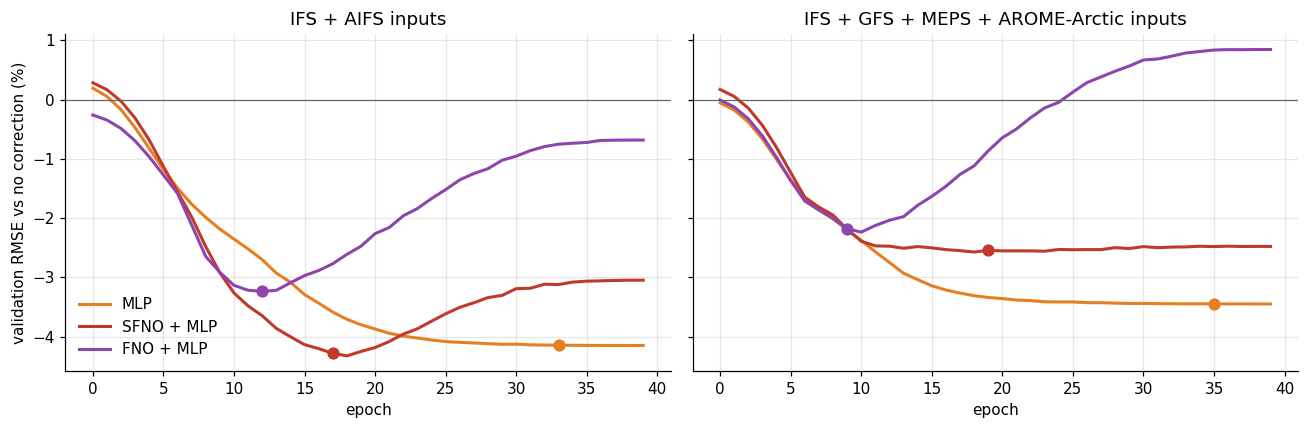

In [5]:
COL = {'MLP': '#e67e22', 'SFNO + MLP': '#c0392b', 'FNO + MLP': '#8e44ad'}
fig, ax = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
for lab, h in H.items():
    a = ax[0] if 'IFS + AIFS' in lab else ax[1]
    v = np.stack(h.val_pct).mean(0)
    c = COL[lab.split(' · ')[0]]
    a.plot(v, color=c, lw=2, label=lab.split(' · ')[0])
    b = int(np.median(h.best_epoch))
    a.plot(b, v[b], 'o', color=c, ms=7)
for a, t in zip(ax, ('IFS + AIFS inputs', 'IFS + GFS + MEPS + AROME-Arctic inputs')):
    a.axhline(0, color='0.4', lw=.8); a.set(title=t, xlabel='epoch')
ax[0].set_ylabel('validation RMSE vs no correction (%)'); ax[0].legend()
plt.tight_layout()

tab = pd.DataFrame({lab: {'parameters': int(h.n_params.iloc[0]), 's / epoch': h.sec.map(np.mean).mean(),
                          'kept epoch (median)': int(np.median(h.best_epoch)),
                          'kept epoch (range)': f'{min(h.best_epoch)}–{max(h.best_epoch)}',
                          'val change at kept epoch (%)': np.mean([v[b] for v, b in zip(h.val_pct, h.best_epoch)]),
                          'val change at epoch 40 (%)': np.mean([v[-1] for v in h.val_pct]),
                          'train change at epoch 40 (%)': np.mean([t[-1] for t in h.train_pct])}
                    for lab, h in H.items()}).T
tab.round(2)

## 3 · Learning rate

The same model at different peak learning rates (one-cycle schedule: the rate rises to the peak
over the first 30 % of the steps and then decays to almost zero). Mean over the runs (15 runs at
$10^{-3}$, $3\cdot10^{-5}$ and $10^{-5}$ for SFNO, 5 runs = seed 0 otherwise). First the raw loss
(logarithmic axis for training: at $10^{-3}$ the training loss falls by an order of magnitude), then
the change against no correction.

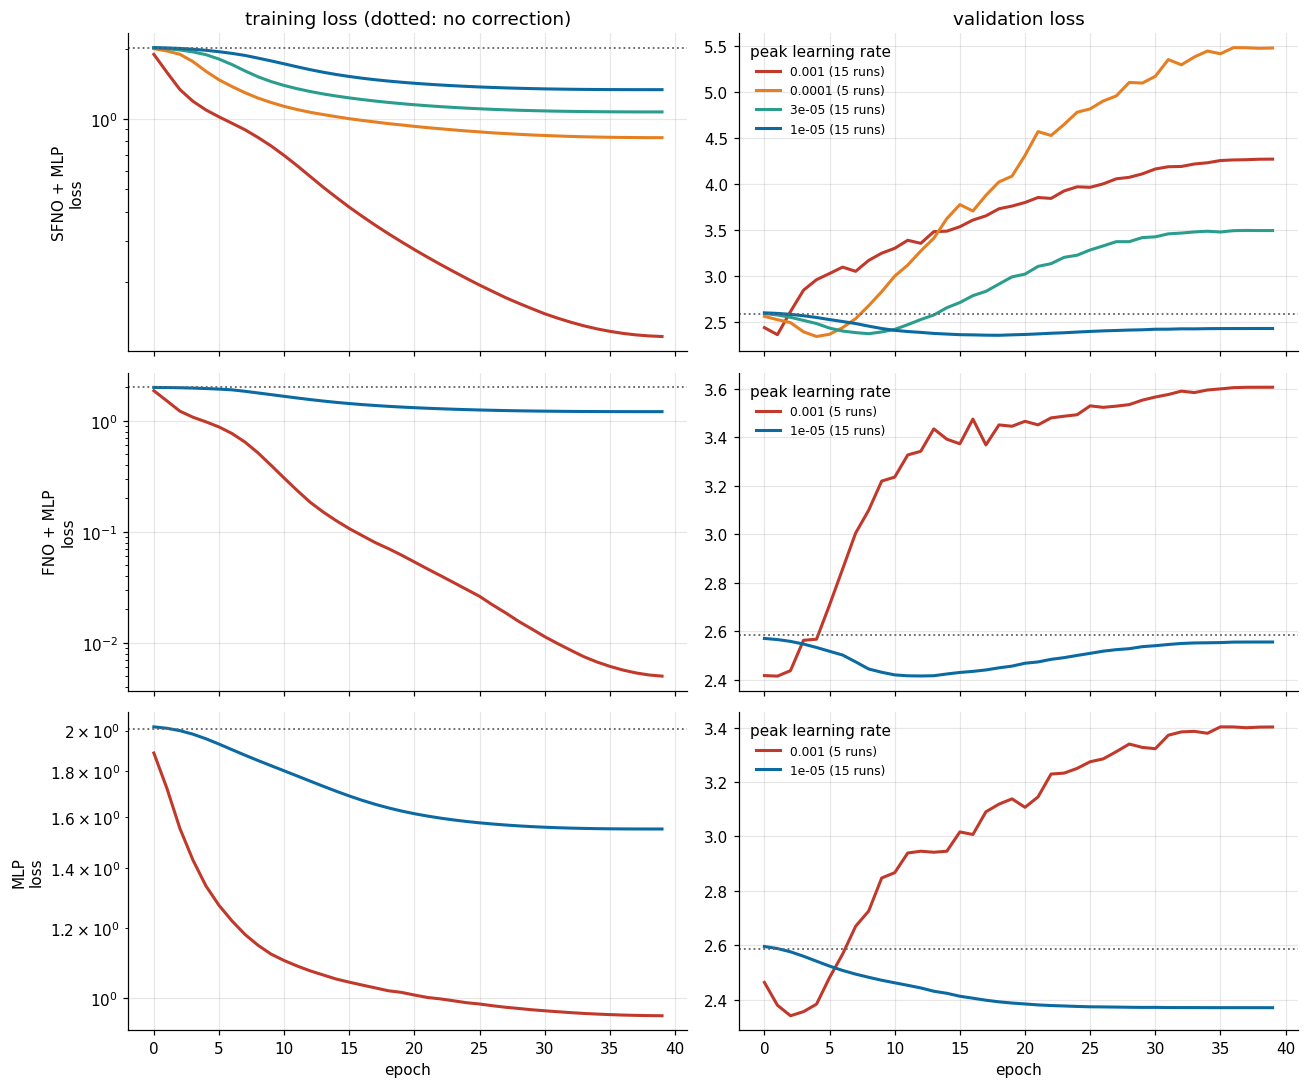

In [6]:
LR = {'SFNO + MLP': {1e-3: 'sfno_terrain_g{k}_s{s}', 1e-4: 'sfno_terrain_g{k}_s{s}_lr0.0001',
                     3e-5: 'sfno_terrain_g{k}_s{s}_lr3e-05', 1e-5: 'sfno_terrain_g{k}_s{s}_lr1e-05'},
      'FNO + MLP': {1e-3: 'fno_terrain_g{k}_s{s}', 1e-5: 'fno_terrain_g{k}_s{s}_lr1e-05'},
      'MLP': {1e-3: 'point_terrain_g{k}_s{s}', 1e-5: 'point_terrain_g{k}_s{s}_lr1e-05'}}
LRC = {1e-3: '#c0392b', 1e-4: '#e67e22', 3e-5: '#2a9d8f', 1e-5: '#0b6aa2'}
HL = {(m, lr): curves(p) for m, d in LR.items() for lr, p in d.items()}

fig, axs = plt.subplots(3, 2, figsize=(12, 10), sharex=True)
for row, m in zip(axs, LR):
    for lr in LR[m]:
        h = HL[(m, lr)]
        for a, key in zip(row, ('train', 'val')):
            a.plot(np.stack(h[key]).mean(0), color=LRC[lr], lw=2, label=f'{lr:g} ({len(h)} runs)')
    nc = HL[(m, 1e-5)]
    row[0].axhline(np.mean((nc.nc_train / sc.ecmwf.y_std) ** 2), color='0.4', ls=':', lw=1.2)
    row[1].axhline(np.mean((nc.nc_val / sc.ecmwf.y_std) ** 2), color='0.4', ls=':', lw=1.2)
    row[0].set_ylabel(f'{m}\nloss'); row[0].set_yscale('log')
    row[1].legend(title='peak learning rate', fontsize=8)
axs[0, 0].set_title('training loss (dotted: no correction)'); axs[0, 1].set_title('validation loss')
for a in axs[-1]: a.set_xlabel('epoch')
plt.tight_layout()

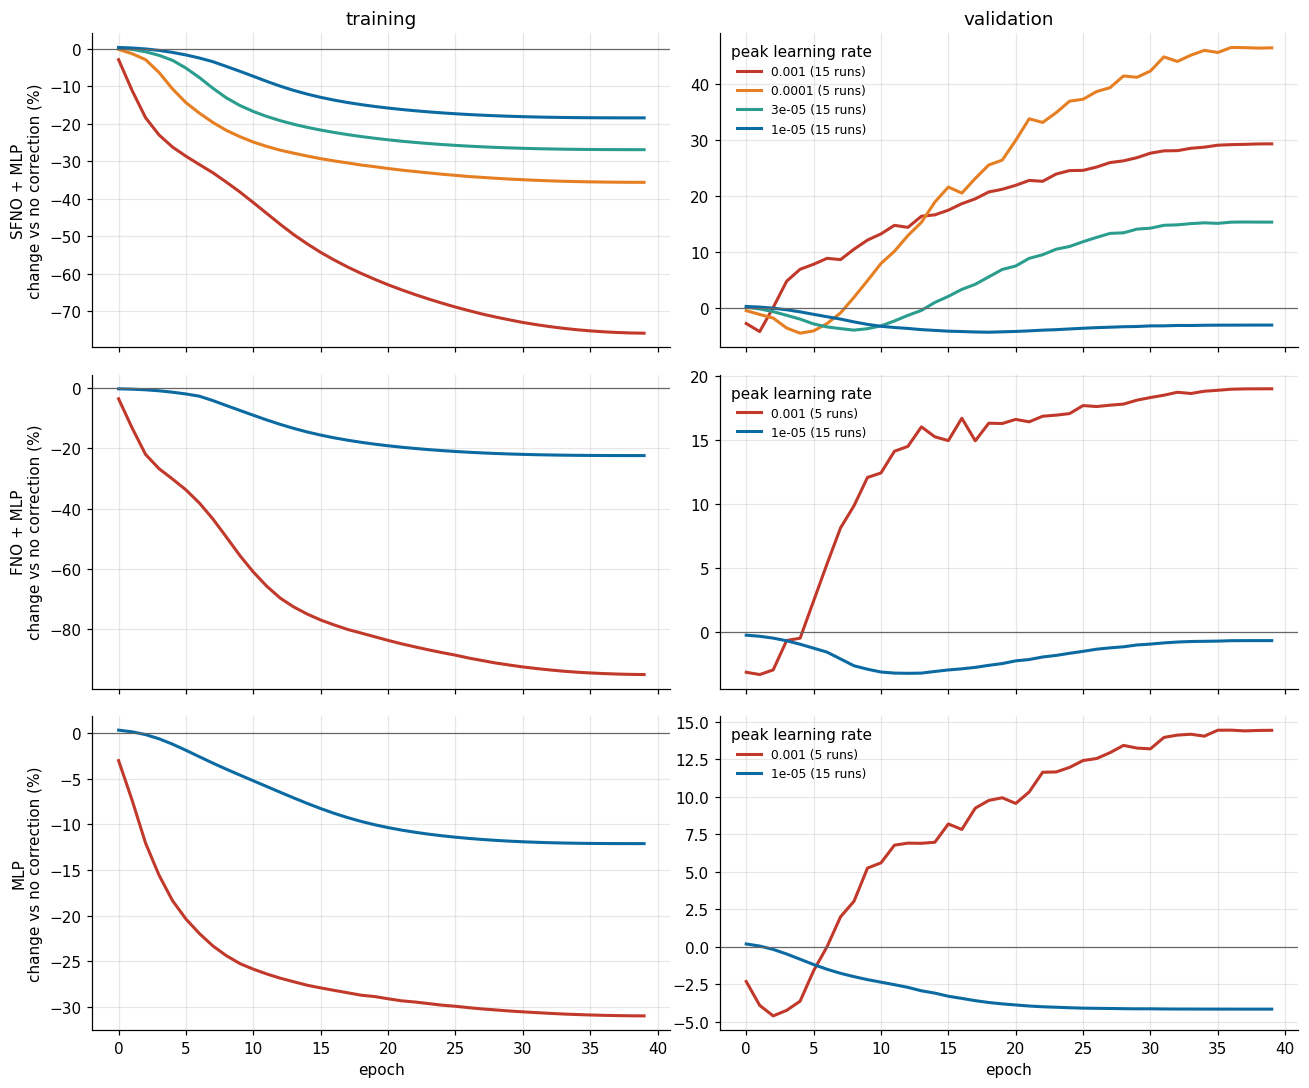

In [7]:
fig, axs = plt.subplots(3, 2, figsize=(12, 10), sharex=True)
for row, m in zip(axs, LR):
    for lr in LR[m]:
        h = HL[(m, lr)]
        for a, key in zip(row, ('train_pct', 'val_pct')):
            a.plot(np.stack(h[key]).mean(0), color=LRC[lr], lw=2, label=f'{lr:g} ({len(h)} runs)')
    row[0].set_ylabel(f'{m}\nchange vs no correction (%)')
    for a in row: a.axhline(0, color='0.4', lw=.8)
    row[1].legend(title='peak learning rate', fontsize=8)
axs[0, 0].set_title('training'); axs[0, 1].set_title('validation')
for a in axs[-1]: a.set_xlabel('epoch')
plt.tight_layout()

Which epoch is kept, and how good it is on validation: every dot is one run.

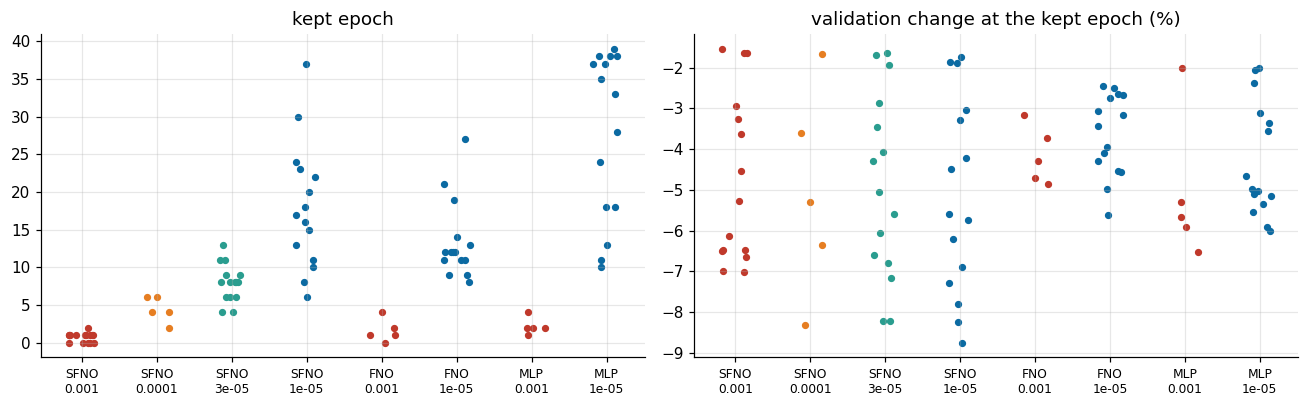

In [8]:
fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
labels = [f"{m.replace(' + MLP', '')}\n{lr:g}" for (m, lr) in HL]
for i, ((m, lr), h) in enumerate(HL.items()):
    jit = np.random.default_rng(i).uniform(-.18, .18, len(h))
    ax[0].scatter(np.full(len(h), i) + jit, h.best_epoch, s=14, color=LRC[lr])
    ax[1].scatter(np.full(len(h), i) + jit, [v[b] for v, b in zip(h.val_pct, h.best_epoch)], s=14, color=LRC[lr])
for a, t in zip(ax, ('kept epoch', 'validation change at the kept epoch (%)')):
    a.set_xticks(range(len(labels)), labels, fontsize=8); a.set_title(t)
plt.tight_layout()

## 4 · Station groups

The held-out groups differ: some are mainly coastal and exposed, others inland. Validation change
per fold for SFNO + MLP and MLP with IFS + AIFS inputs at $10^{-5}$ (mean of the 3 seeds per fold),
and the no-correction RMSE of each group in the validation period.

,MLP · IFS + AIFS,SFNO + MLP · IFS + AIFS,stations,"no correction, val (m/s)"
group,,,,
0,-5.47,-5.85,28,4.18
1,-5.37,-7.33,17,4.65
2,-3.86,-3.60,14,4.59
3,-2.15,-1.83,20,3.98
4,-4.56,-7.08,20,5.04


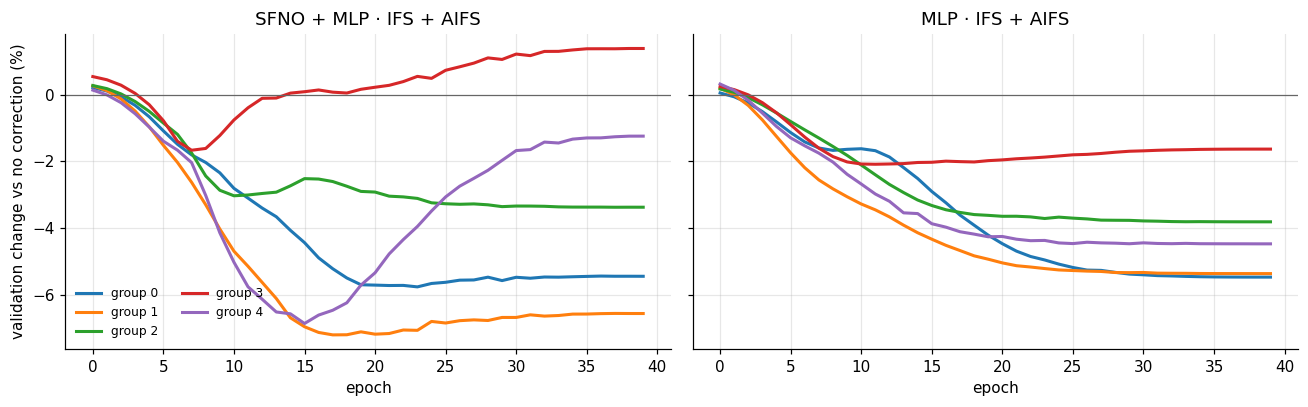

In [9]:
fig, ax = plt.subplots(1, 2, figsize=(12, 3.8), sharey=True)
rows = []
for a, lab in zip(ax, ('SFNO + MLP · IFS + AIFS', 'MLP · IFS + AIFS')):
    h = H[lab]
    for k in range(5):
        hk = h[h.fold == k]
        a.plot(np.stack(hk.val_pct).mean(0), lw=2, label=f'group {k}')
        rows.append({'model': lab, 'group': k, 'stations': int((G == k).sum()),
                     'no correction, val (m/s)': hk.nc_val.iloc[0],
                     'val change at kept epoch (%)': np.mean([v[b] for v, b in zip(hk.val_pct, hk.best_epoch)])})
    a.axhline(0, color='0.4', lw=.8); a.set(title=lab, xlabel='epoch')
ax[0].set_ylabel('validation change vs no correction (%)'); ax[0].legend(fontsize=8, ncol=2)
plt.tight_layout()
pd.DataFrame(rows).pivot_table(index='group', columns='model', values='val change at kept epoch (%)').join(
    pd.DataFrame(rows).groupby('group')[['stations', 'no correction, val (m/s)']].first()).round(2)

## 5 · Validation and test

The checkpoint is chosen on the validation period (winter). Is a run that does well on validation
also good on the test period (spring–summer)? For every run: the validation change at the kept
epoch against the test change on the same held-out group (both against no correction).

correlation over all runs: 0.67


,val,test
set,,
MLP · IFS + AIFS,-4.28,-3.28
SFNO + MLP · IFS + AIFS,-5.14,-4.15
FNO + MLP · IFS + AIFS,-3.65,-2.96
MLP · four models,-3.90,-3.64
SFNO + MLP · four models,-3.25,-2.95
FNO + MLP · four models,-2.76,-2.70
SFNO + MLP · IFS + AIFS · lr 0.001,-4.71,-3.89
SFNO + MLP · IFS + AIFS · lr 0.0001,-5.05,-4.06
SFNO + MLP · IFS + AIFS · lr 3e-05,-4.91,-4.00


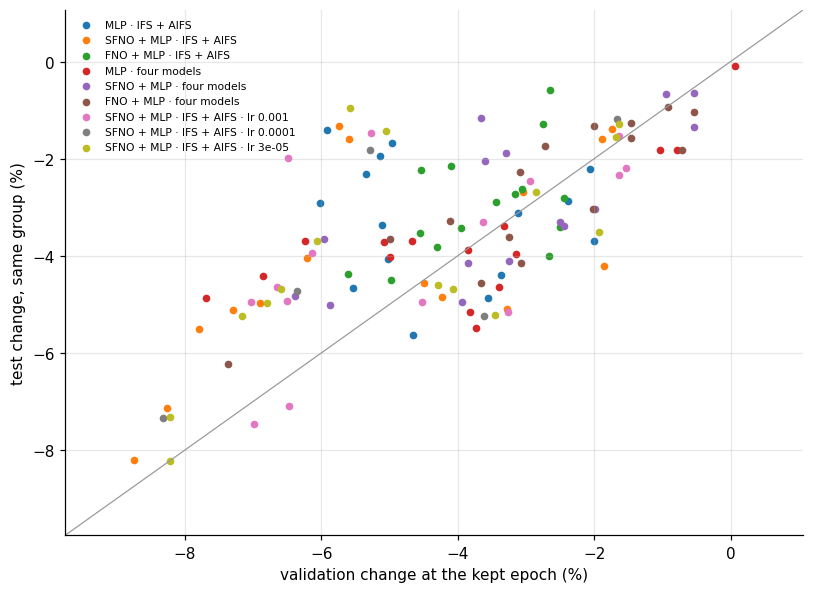

In [10]:
def test_change(row, group):
    # test change vs no correction on the run's own held-out group
    p = np.load(R.RUNS / row.run / 'pred.npz')['test'][sc.te][:, :, :R.N_BASE][:, :, G == row.fold]
    o, b = sc.obs[:, :, G == row.fold], sc.base[group][:, :, G == row.fold]
    m = np.isfinite(o[..., 0]) & np.isfinite(p[..., 0])
    e1, e0 = ((o - b - p) ** 2).sum(-1)[m], ((o - b) ** 2).sum(-1)[m]
    return (np.sqrt(e1.mean() / e0.mean()) - 1) * 100

SETS = dict(H) | {f'SFNO + MLP · IFS + AIFS · lr {lr:g}': HL[('SFNO + MLP', lr)] for lr in (1e-3, 1e-4, 3e-5)}
pts = []
for lab, h in SETS.items():
    g = 'nwp' if 'four models' in lab else 'ecmwf'
    for row in h.itertuples():
        pts.append({'set': lab, 'fold': row.fold, 'val': row.val_pct[row.best_epoch], 'test': test_change(row, g)})
pts = pd.DataFrame(pts)

fig, ax = plt.subplots(figsize=(7.5, 5.5))
for lab, d in pts.groupby('set', sort=False):
    ax.scatter(d.val, d.test, s=16, label=lab)
lim = [min(pts.val.min(), pts.test.min()) - 1, max(pts.val.max(), pts.test.max()) + 1]
ax.plot(lim, lim, color='0.6', lw=.8)
ax.set(xlabel='validation change at the kept epoch (%)', ylabel='test change, same group (%)', xlim=lim, ylim=lim)
ax.legend(fontsize=7, loc='upper left')
plt.tight_layout()
print(f'correlation over all runs: {np.corrcoef(pts.val, pts.test)[0, 1]:.2f}')
pts.groupby('set', sort=False)[['val', 'test']].mean().round(2)

## Summary

* **The models overfit to the training stations.** The training error keeps falling to epoch 40
  (−12 % for MLP to −22 % for FNO + MLP against no correction), while the validation error on the
  held-out group improves by only 2.8–5.1 % at the kept epoch. Generalising to new stations,
  not fitting the training stations, is the limit.
* **Operators overfit more than the MLP.** At $10^{-5}$ the MLP's validation error falls steadily
  and stays at its minimum (kept epoch about 33). SFNO + MLP reaches a lower minimum around epoch
  17 and then loses a third of its gain. FNO + MLP reaches its minimum around epoch 12 and loses
  almost all of it (four-model inputs: worse than no correction by epoch 40). For the operators the
  checkpoint chosen on validation is essential.
* **Learning rate.** At $10^{-3}$ the training error collapses (−76 % for SFNO + MLP) and the
  validation error is lowest after 0–2 epochs, then rises to +30 %. The model kept is a barely
  trained one. Lower rates move the minimum later and make it flatter; at $10^{-5}$ the curves are
  smooth. With the checkpoint selection all rates end up within about 0.5 percentage points on
  the test period (`02_experiments.ipynb`).
* **Station groups differ.** The easternmost group (3) is the hardest: about −2 % on validation for
  both models, and SFNO + MLP is worse than no correction there by epoch 40. Groups 1 and 4 gain
  about −7 % with SFNO + MLP.
* **Validation predicts test.** Over all runs, the validation change at the kept epoch and the test
  change on the same group correlate with r = 0.67. Validation (winter) shows larger gains than test
  (spring–summer), by up to 1 percentage point. Within each input group, the three networks rank
  in the same order on validation and on test.